<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_3_SQL/Projects/Instructions/Project.3-SQL/SQL_1_Chinook_Phase_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project SQL: Data Discovery with the Chinook Database

Welcome to your first major hands-on data exploration project. In this assignment, you will be stepping into the role of a data analyst querying the Chinook database: a sample dataset representing a digital media store, complete with information about artists, albums, tracks, customers, and business sales.

The core objective of this project is to transition you from simply writing code to thinking like a data scientist. To do that, our journey follows a deliberate, four-fold progression:



### Phase 1. Master the Mechanics (Get Familiar with SQL)



Before you can extract deep insights, you need to speak the language. You will start by practicing the fundamental mechanics of SQL using the SQL statements below: learning how to filter data, join tables, group metrics, and aggregate numbers. Think of this as learning how to move around the data environment smoothly.  As a starting point, pick a single table and answer the "How many ...?" questions using SQL.  Then repeat the process for each table.



## Why This Matters: The Path to Your Capstone


Learning to ask your own questions is the exact skill you will rely on for your final capstone project. In your capstone, you will choose a dataset from your own field of interest. No one will hand you a list of prompts or a guide telling you what to look for.

Use this project as your sandbox. Mastering the ability to interrogate a database now will give you the framework you need to discover meaningful, independent insights in your capstone later.



## Chinook data set

See the lecture on SQLite3 using the Chinook data set to set up the software, database, and tables, as well as for the links to ancillary information about the data set.


In [45]:
# Load the modules
import sqlite3 as db
import pandas as pd
import contextlib
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Install the sqlite package for Ubuntu
%%capture
%%bash
apt-get update
apt-get install -y sqlite3


In [3]:
# Download the Chinook sqlite database

In [4]:
%%bash
[ -f chinook.zip ] ||
  curl -s -O https://www.sqlitetutorial.net/wp-content/uploads/2018/03/chinook.zip
unzip -l chinook.zip


Archive:  chinook.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
   884736  2015-11-29 10:53   chinook.db
---------                     -------
   884736                     1 file


In [5]:
!rm -f chinook.db


In [6]:
!unzip -u chinook.zip


Archive:  chinook.zip
  inflating: chinook.db              


In [7]:
!ls -l

total 1168
-rw-r--r-- 1 root root 884736 Nov 29  2015 chinook.db
-rw-r--r-- 1 root root 305596 Nov 16 01:21 chinook.zip
drwxr-xr-x 1 root root   4096 Nov 12 16:40 sample_data


In [8]:
!ls -l *.db

-rw-r--r-- 1 root root 884736 Nov 29  2015 chinook.db


## Use SQL queries to pull specific information

Do NOT pull all the data and then filter using DataFrame methods.  The initial purpose is to get familiar with SQL.




In [9]:
%%script sqlite3 --column --header chinook.db
.schema

CREATE TABLE IF NOT EXISTS "albums"
(
    [AlbumId] INTEGER PRIMARY KEY AUTOINCREMENT NOT NULL,
    [Title] NVARCHAR(160)  NOT NULL,
    [ArtistId] INTEGER  NOT NULL,
    FOREIGN KEY ([ArtistId]) REFERENCES "artists" ([ArtistId]) 
		ON DELETE NO ACTION ON UPDATE NO ACTION
);
CREATE TABLE sqlite_sequence(name,seq);
CREATE TABLE IF NOT EXISTS "artists"
(
    [ArtistId] INTEGER PRIMARY KEY AUTOINCREMENT NOT NULL,
    [Name] NVARCHAR(120)
);
CREATE TABLE IF NOT EXISTS "customers"
(
    [CustomerId] INTEGER PRIMARY KEY AUTOINCREMENT NOT NULL,
    [FirstName] NVARCHAR(40)  NOT NULL,
    [LastName] NVARCHAR(20)  NOT NULL,
    [Company] NVARCHAR(80),
    [Address] NVARCHAR(70),
    [City] NVARCHAR(40),
    [State] NVARCHAR(40),
    [Country] NVARCHAR(40),
    [PostalCode] NVARCHAR(10),
    [Phone] NVARCHAR(24),
    [Fax] NVARCHAR(24),
    [Email] NVARCHAR(60)  NOT NULL,
    [SupportRepId] INTEGER,
    FOREIGN KEY ([SupportRepId]) REFERENCES "employees" ([EmployeeId]) 
		ON DELETE NO ACTION ON 

In [10]:
%%script sqlite3 --column --header chinook.db
.tables

albums          employees       invoices        playlists     
artists         genres          media_types     tracks        
customers       invoice_items   playlist_track


### Basic Queries


#### SELECT (with * and with column names)


In [11]:
# Select all from employees
%%script sqlite3 --column --header chinook.db
SELECT *
FROM employees;

Title                                
-------------------------------------
For Those About To Rock We Salute You
Balls to the Wall                    
Restless and Wild                    
Let There Be Rock                    
Big Ones                             
Jagged Little Pill                   
Facelift                             
Warner 25 Anos                       
Plays Metallica By Four Cellos       
Audioslave                           


In [12]:
# Select all from customers
%%script sqlite3 --column --header chinook.db
SELECT *
FROM customers
LIMIT 10;

ArtistId  Name                                                                                 
--------  -------------------------------------------------------------------------------------
213       Scholars Baroque Ensemble                                                            
214       Academy of St. Martin in the Fields & Sir Neville Marriner                           
215       Academy of St. Martin in the Fields Chamber Ensemble & Sir Neville Marriner          
216       Berliner Philharmoniker, Claudio Abbado & Sabine Meyer                               
217       Royal Philharmonic Orchestra & Sir Thomas Beecham                                    
218       Orchestre Révolutionnaire et Romantique & John Eliot Gardiner                        
219       Britten Sinfonia, Ivor Bolton & Lesley Garrett                                       
220       Chicago Symphony Chorus, Chicago Symphony Orchestra & Sir Georg Solti                
221       Sir Georg Solti & Wiener Philh

In [13]:
# Select all from genres
%%script sqlite3 --column --header chinook.db
SELECT *
FROM genres;

CustomerId  FirstName  LastName      Company                                           Address                                   City                 State   Country         PostalCode  Phone                Fax                 Email                          SupportRepId
----------  ---------  ------------  ------------------------------------------------  ----------------------------------------  -------------------  ------  --------------  ----------  -------------------  ------------------  -----------------------------  ------------
1           Luís       Gonçalves     Embraer - Empresa Brasileira de Aeronáutica S.A.  Av. Brigadeiro Faria Lima, 2170           São José dos Campos  SP      Brazil          12227-000   +55 (12) 3923-5555   +55 (12) 3923-5566  luisg@embraer.com.br           3           
2           Leonie     Köhler                                                          Theodor-Heuss-Straße 34                   Stuttgart                    Germany         70174       +

In [14]:
# Select FirstName, LastName, Title, and Email from employees
%%script sqlite3 --column --header chinook.db
SELECT FirstName, LastName, Title, Email
FROM employees;

EmployeeId  LastName  FirstName  Title                ReportsTo  BirthDate            HireDate             Address                      City        State  Country  PostalCode  Phone              Fax                Email                   
----------  --------  ---------  -------------------  ---------  -------------------  -------------------  ---------------------------  ----------  -----  -------  ----------  -----------------  -----------------  ------------------------
1           Adams     Andrew     General Manager                 1962-02-18 00:00:00  2002-08-14 00:00:00  11120 Jasper Ave NW          Edmonton    AB     Canada   T5K 2N1     +1 (780) 428-9482  +1 (780) 428-3457  andrew@chinookcorp.com  
2           Edwards   Nancy      Sales Manager        1          1958-12-08 00:00:00  2002-05-01 00:00:00  825 8 Ave SW                 Calgary     AB     Canada   T2P 2T3     +1 (403) 262-3443  +1 (403) 262-3322  nancy@chinookcorp.com   
3           Peacock   Jane       Sales Suppo

In [15]:
# Select AlbumID and Title from albums
%%script sqlite3 --column --header chinook.db
SELECT AlbumId, Title
FROM albums
LIMIT 10;

GenreId  Name              
-------  ------------------
1        Rock              
2        Jazz              
3        Metal             
4        Alternative & Punk
5        Rock And Roll     
6        Blues             
7        Latin             
8        Reggae            
9        Pop               
10       Soundtrack        
11       Bossa Nova        
12       Easy Listening    
13       Heavy Metal       
14       R&B/Soul          
15       Electronica/Dance 
16       World             
17       Hip Hop/Rap       
18       Science Fiction   
19       TV Shows          
20       Sci Fi & Fantasy  
21       Drama             
22       Comedy            
23       Alternative       
24       Classical         
25       Opera             


In [16]:
# Select UnitPrice and Quantity from invoice_items
%%script sqlite3 --column --header chinook.db
SELECT UnitPrice, Quantity
FROM invoice_items
LIMIT 10;

UnitPrice  Quantity
---------  --------
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       
0.99       1       


In [17]:
# Rename output columns using AS
%%script sqlite3 --column --header chinook.db
SELECT
    FirstName AS First_Name,
    LastName AS Last_Name,
    Country AS Customer_Country,
    Email AS Contact_Email
FROM customers
LIMIT 10;

CustomerId  FirstName  LastName     Company                                           Address                               City                 State  Country         PostalCode  Phone               Fax                 Email                     SupportRepId
----------  ---------  -----------  ------------------------------------------------  ------------------------------------  -------------------  -----  --------------  ----------  ------------------  ------------------  ------------------------  ------------
1           Luís       Gonçalves    Embraer - Empresa Brasileira de Aeronáutica S.A.  Av. Brigadeiro Faria Lima, 2170       São José dos Campos  SP     Brazil          12227-000   +55 (12) 3923-5555  +55 (12) 3923-5566  luisg@embraer.com.br      3           
2           Leonie     Köhler                                                         Theodor-Heuss-Straße 34               Stuttgart                   Germany         70174       +49 0711 2842222                        leo

#### WHERE


In [27]:
# Find customers in Brazil
%%script sqlite3 --column --header chinook.db
SELECT FirstName, LastName, City, Country
FROM customers
WHERE Country = 'Brazil';

FirstName  LastName   City                 Country
---------  ---------  -------------------  -------
Luís       Gonçalves  São José dos Campos  Brazil 
Eduardo    Martins    São Paulo            Brazil 
Alexandre  Rocha      São Paulo            Brazil 
Roberto    Almeida    Rio de Janeiro       Brazil 
Fernanda   Ramos      Brasília             Brazil 


#### AND


In [28]:
# Find invoices from USA with total greater than $10.00
%%script sqlite3 --column --header chinook.db
SELECT InvoiceId, CustomerId, BillingCountry, Total
FROM invoices
WHERE BillingCountry = 'USA' AND Total > 10;

InvoiceId  CustomerId  BillingCountry  Total
---------  ----------  --------------  -----
5          23          USA             13.86
26         19          USA             13.86
82         28          USA             13.86
103        24          USA             15.86
124        20          USA             13.86
145        16          USA             13.86
201        25          USA             18.86
222        21          USA             13.86
243        17          USA             13.86
298        17          USA             10.91
299        26          USA             23.86
311        28          USA             11.94
320        22          USA             13.86
341        18          USA             13.86
397        27          USA             13.86


#### OR


In [29]:
# Find tracks that belong to either Rock or Jazz
%%script sqlite3 --column --header chinook.db
SELECT TrackId, Name, GenreId, UnitPrice
FROM tracks
WHERE GenreId = 1 OR GenreId = 2
LIMIT 15;

TrackId  Name                                     GenreId  UnitPrice
-------  ---------------------------------------  -------  ---------
1        For Those About To Rock (We Salute You)  1        0.99     
2        Balls to the Wall                        1        0.99     
3        Fast As a Shark                          1        0.99     
4        Restless and Wild                        1        0.99     
5        Princess of the Dawn                     1        0.99     
6        Put The Finger On You                    1        0.99     
7        Let's Get It Up                          1        0.99     
8        Inject The Venom                         1        0.99     
9        Snowballed                               1        0.99     
10       Evil Walks                               1        0.99     
11       C.O.D.                                   1        0.99     
12       Breaking The Rules                       1        0.99     
13       Night Of The Long Knives 

#### LIKE (with % or _ wildcard)


In [32]:
# Find tracks with "Love" anywhere in the title
%%script sqlite3 --column --header chinook.db
SELECT TrackId, Name, Composer
FROM tracks
WHERE Name LIKE '%Love%'
LIMIT 15;

TrackId  Name                                          Composer                                                        
-------  --------------------------------------------  ----------------------------------------------------------------
24       Love In An Elevator                           Steven Tyler, Joe Perry                                         
56       Love, Hate, Love                              Jerry Cantrell, Layne Staley                                    
195      Let Me Love You Baby                          Willie Dixon                                                    
335      My Love                                       Jauperi/Zeu Góes                                                
341      The Girl I Love She Got Long Black Wavy Hair  Jimmy Page/John Bonham/John Estes/John Paul Jones/Robert Plant  
345      Whole Lotta Love                              Jimmy Page/John Bonham/John Paul Jones/Robert Plant/Willie Dixon
413      Loverman                       

#### BETWEEN


In [33]:
# Find invoices with the date in year 2010
%%script sqlite3 --column --header chinook.db
SELECT InvoiceId, InvoiceDate, BillingCountry, Total
FROM invoices
WHERE InvoiceDate BETWEEN '2010-01-01' AND '2010-12-31'
LIMIT 15;

InvoiceId  InvoiceDate          BillingCountry  Total
---------  -------------------  --------------  -----
84         2010-01-08 00:00:00  France          1.98 
85         2010-01-08 00:00:00  Hungary         1.98 
86         2010-01-09 00:00:00  Italy           3.96 
87         2010-01-10 00:00:00  Sweden          6.94 
88         2010-01-13 00:00:00  Chile           17.91
89         2010-01-18 00:00:00  Austria         18.86
90         2010-01-26 00:00:00  USA             0.99 
91         2010-02-08 00:00:00  USA             1.98 
92         2010-02-08 00:00:00  USA             1.98 
93         2010-02-09 00:00:00  USA             3.96 
94         2010-02-10 00:00:00  Canada          5.94 
95         2010-02-13 00:00:00  Germany         8.91 
96         2010-02-18 00:00:00  Hungary         21.86
97         2010-02-26 00:00:00  India           1.99 
98         2010-03-11 00:00:00  Brazil          3.98 


#### LIMIT



In [34]:
# Display the first 10 albums
%%script sqlite3 --column --header chinook.db
SELECT AlbumId, Title, ArtistId
FROM albums
LIMIT 10;

AlbumId  Title                                  ArtistId
-------  -------------------------------------  --------
1        For Those About To Rock We Salute You  1       
2        Balls to the Wall                      2       
3        Restless and Wild                      2       
4        Let There Be Rock                      1       
5        Big Ones                               3       
6        Jagged Little Pill                     4       
7        Facelift                               5       
8        Warner 25 Anos                         6       
9        Plays Metallica By Four Cellos         7       
10       Audioslave                             8       


### Sorting and Grouping


#### ORDER BY


In [35]:
# List the 10 longest tracks
%%script sqlite3 --column --header chinook.db
SELECT Name, Composer, Milliseconds, UnitPrice
FROM tracks
ORDER BY Milliseconds DESC
LIMIT 10;

Name                         Composer  Milliseconds  UnitPrice
---------------------------  --------  ------------  ---------
Occupation / Precipice                 5286953       1.99     
Through a Looking Glass                5088838       1.99     
Greetings from Earth, Pt. 1            2960293       1.99     
The Man With Nine Lives                2956998       1.99     
Battlestar Galactica, Pt. 2            2956081       1.99     
Battlestar Galactica, Pt. 1            2952702       1.99     
Murder On the Rising Star              2935894       1.99     
Battlestar Galactica, Pt. 3            2927802       1.99     
Take the Celestra                      2927677       1.99     
Fire In Space                          2926593       1.99     


#### DISTINCT


In [38]:
# Unique list of all countries from customers
%%script sqlite3 --column --header chinook.db
SELECT DISTINCT Country
FROM customers
ORDER BY Country ASC;

Country       
--------------
Argentina     
Australia     
Austria       
Belgium       
Brazil        
Canada        
Chile         
Czech Republic
Denmark       
Finland       
France        
Germany       
Hungary       
India         
Ireland       
Italy         
Netherlands   
Norway        
Poland        
Portugal      
Spain         
Sweden        
USA           
United Kingdom


#### GROUP BY



In [39]:
# Count of how many customers in each country
%%script sqlite3 --column --header chinook.db
SELECT Country, COUNT(CustomerId) AS CustomerCount
FROM customers
GROUP BY Country
ORDER BY CustomerCount DESC;

Country         CustomerCount
--------------  -------------
USA             13           
Canada          8            
France          5            
Brazil          5            
Germany         4            
United Kingdom  3            
Portugal        2            
India           2            
Czech Republic  2            
Sweden          1            
Spain           1            
Poland          1            
Norway          1            
Netherlands     1            
Italy           1            
Ireland         1            
Hungary         1            
Finland         1            
Denmark         1            
Chile           1            
Belgium         1            
Austria         1            
Australia       1            
Argentina       1            


### Aggregates


#### MAX


In [40]:
# Highest single invoice total
%%script sqlite3 --column --header chinook.db
SELECT MAX(Total) AS Highest_Invoice
FROM invoices;

Highest_Invoice
---------------
25.86          


#### MIN


In [41]:
# Lowest single invoice total
%%script sqlite3 --column --header chinook.db
SELECT MIN(Total) AS Lowest_Invoice
FROM invoices;

Lowest_Invoice
--------------
0.99          


#### SUM


In [42]:
# Total lifetime revenue across all invoices
%%script sqlite3 --column --header chinook.db
SELECT SUM(Total) AS Total_Revenue
FROM invoices;

Total_Revenue
-------------
2328.6       


#### AVG


In [43]:
# Average invoice amount
%%script sqlite3 --column --header chinook.db
SELECT ROUND(AVG(Total), 2) AS Average_Invoice
FROM invoices;

Average_Invoice
---------------
5.65           


#### COUNT



In [44]:
# Total number of tracks
%%script sqlite3 --column --header chinook.db
SELECT COUNT(*) AS Total_Tracks
FROM tracks;

Total_Tracks
------------
3503        


In [ ]:
conn = db.connect('chinook.db')

In [ ]:
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
""", conn)

In [ ]:
for table in tables['name']:
    query = f"SELECT COUNT(*) FROM '{table}'"
    result = pd.read_sql_query(query, conn)

    print(f"{table}: {result.iloc[0, 0]} records")

albums: 347 records
sqlite_sequence: 10 records
artists: 275 records
customers: 59 records
employees: 8 records
genres: 25 records
invoices: 412 records
invoice_items: 2240 records
media_types: 5 records
playlists: 18 records
playlist_track: 8715 records
tracks: 3503 records
sqlite_stat1: 15 records


## Make some plots

Make some cool plots to go with your data. Write SQL queries to get ONLY the information you need for each plot. (Don't pull ALL the data and then just plot a few columns.)



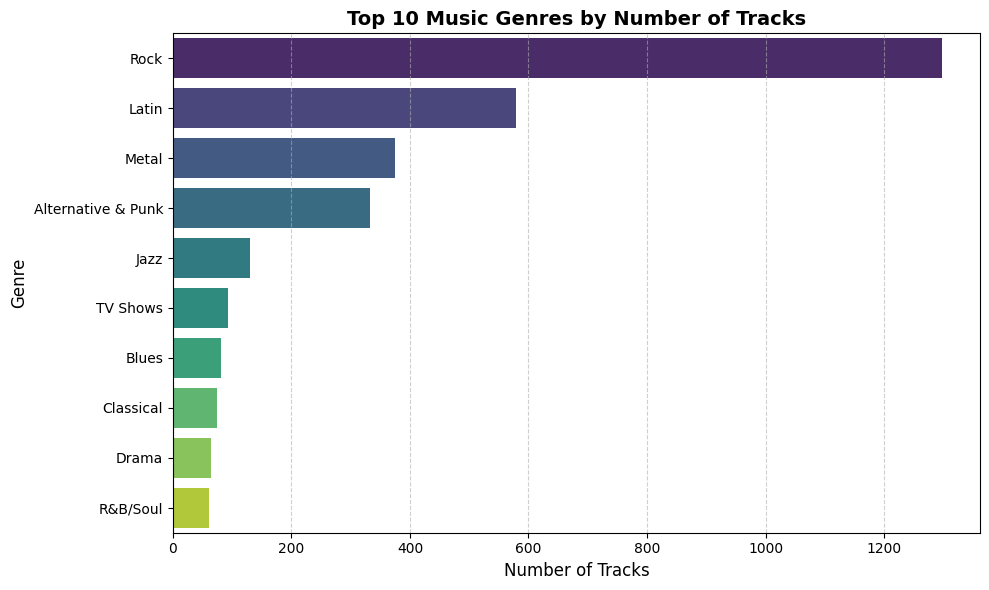

In [47]:
# Connect to database and run query
conn = db.connect('chinook.db')
query_genres = """
SELECT g.Name AS Genre, COUNT(t.TrackId) AS TrackCount
FROM genres g
JOIN tracks t ON g.GenreId = t.GenreId
GROUP BY g.Name
ORDER BY TrackCount DESC
LIMIT 10;
"""
df_genres = pd.read_sql_query(query_genres, conn)
conn.close()

# Plot top 10 music genres by number of tracks
plt.figure(figsize=(10, 6))
sns.barplot(data=df_genres, x='TrackCount', y='Genre', palette='viridis', hue='Genre', legend=False)
plt.title('Top 10 Music Genres by Number of Tracks', fontsize=14, fontweight='bold')
plt.xlabel('Number of Tracks', fontsize=12)
plt.ylabel('Genre', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

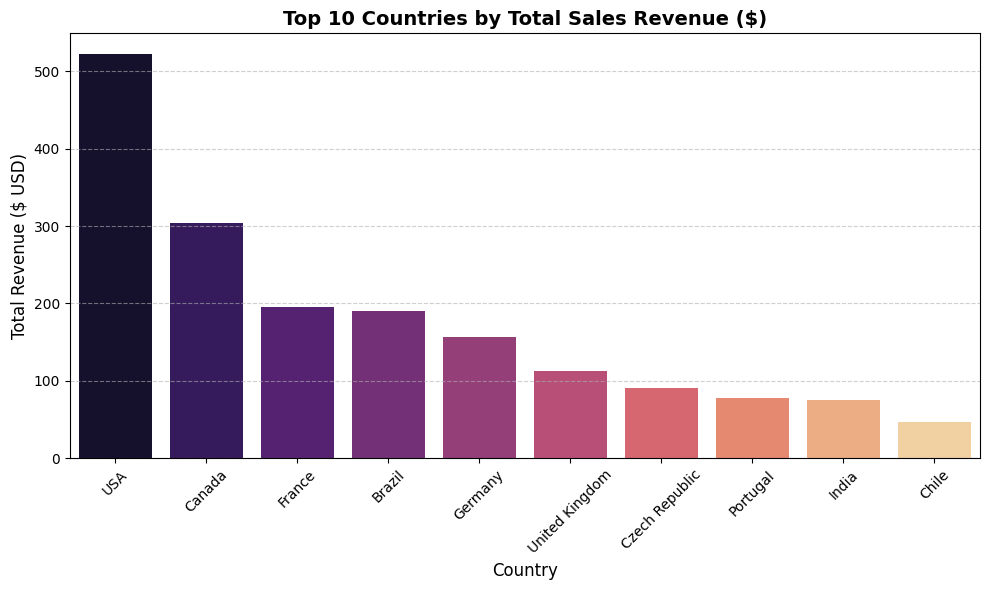

In [50]:
# Connect to database and run query
conn = db.connect('chinook.db')
query_revenue = """
SELECT BillingCountry AS Country, ROUND(SUM(Total), 2) AS TotalRevenue
FROM invoices
GROUP BY BillingCountry
ORDER BY TotalRevenue DESC
LIMIT 10;
"""
df_revenue = pd.read_sql_query(query_revenue, conn)
conn.close()

# Plot top 10 countires by total sales revenue ($)
plt.figure(figsize=(10, 6))
sns.barplot(data=df_revenue, x='Country', y='TotalRevenue', palette='magma', hue='Country', legend=False)
plt.title('Top 10 Countries by Total Sales Revenue ($)', fontsize=14, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Revenue ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

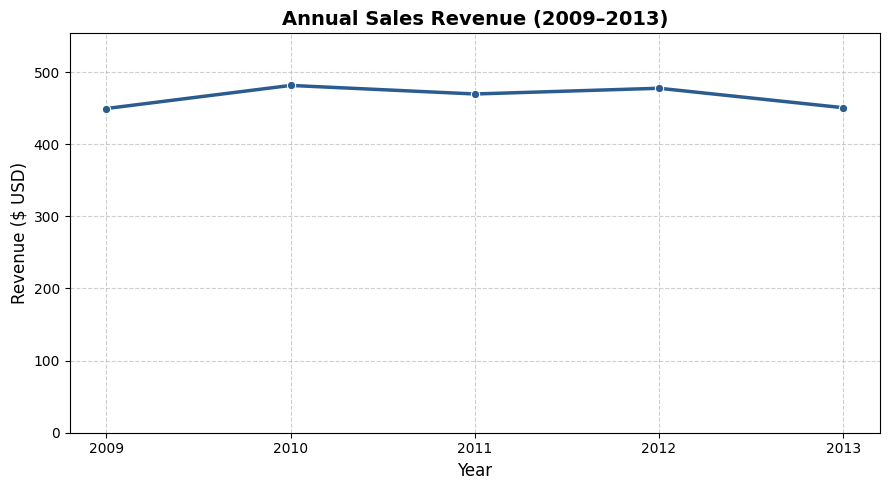

In [52]:
# Connect to database and run query
conn = db.connect('chinook.db')
query_yearly = """
SELECT STRFTIME('%Y', InvoiceDate) AS Year, ROUND(SUM(Total), 2) AS AnnualRevenue
FROM invoices
GROUP BY Year
ORDER BY Year ASC;
"""
df_yearly = pd.read_sql_query(query_yearly, conn)
conn.close()

# Plot annual sales revenue (2009 - 2013)
plt.figure(figsize=(9, 5))
sns.lineplot(data=df_yearly, x='Year', y='AnnualRevenue', marker='o', linewidth=2.5, color='#2b5c8f')
plt.title('Annual Sales Revenue (2009–2013)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Revenue ($ USD)', fontsize=12)
plt.ylim(0, df_yearly['AnnualRevenue'].max() * 1.15)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## EXTRA CREDIT:
* Use a CTE
* Use a query that joins two or more tables.
* Make a model to see if you can predict something ( e.g. GNB classifier, linear regression )
* Come up with something else cool to do with your data
